<a href="https://colab.research.google.com/github/emrizky1/PCVK_Ganjil_2026/blob/main/week7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

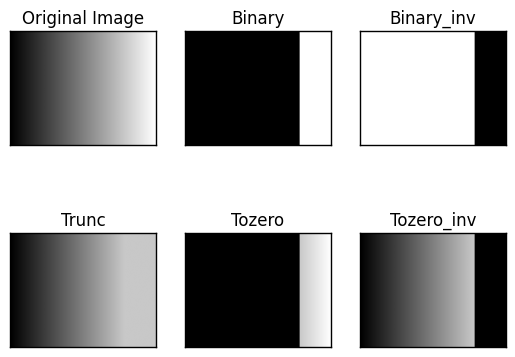

In [ ]:
img = np.tile(np.arange(256, dtype=np.uint8), (200, 1))

thresh = 200
maxval = 255

binary = np.where(img > thresh, maxval, 0).astype(np.uint8)
binary_inv = np.where(img > thresh, 0, maxval).astype(np.uint8)
trunc = np.where(img > thresh, thresh, img).astype(np.uint8)
tozero = np.where(img > thresh, img, 0).astype(np.uint8)
tozero_inv = np.where(img > thresh, 0, img).astype(np.uint8)

titles = ['Original Image', 'Binary', 'Binary_inv', 'Trunc', 'Tozero', 'Tozero_inv']
images = [img, binary, binary_inv, trunc, tozero, tozero_inv]

for i in range(6):
    ax = plt.subplot(2, 3, i+1)
    ax.imshow(images[i], cmap='gray', vmin=0, vmax=255)
    ax.set_title(titles[i])
    ax.set_xticks([])
    ax.set_yticks([])

    for spine in ax.spines.values():
      spine.set_edgecolor('black')
      spine.set_linewidth(1)
plt.show()

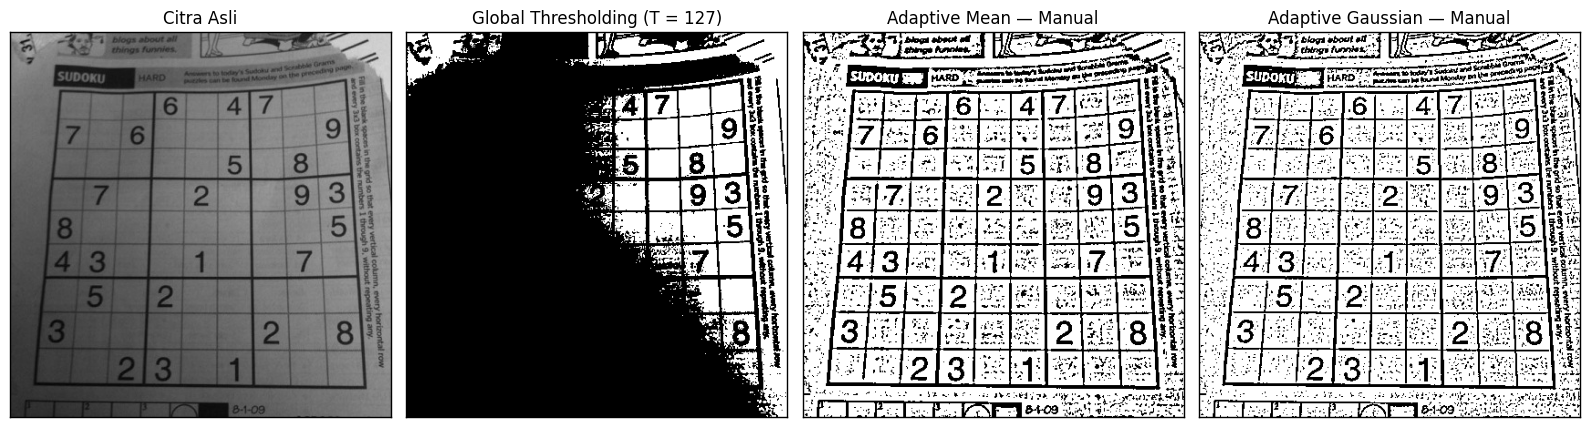

In [ ]:
img = cv.imread('/content/drive/MyDrive/pcvk_2026/Images/sudoku-original.jpg')
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
H, W = gray.shape

def konvolusi_manual(img, kernel):
  k = kernel.shape[0]
  pad = k // 2
  padded = np.pad(img.astype(np.float32), pad, mode='reflect')
  out = np.zeros((H, W), dtype=np.float32)
  for i in range(k):
    for j in range(k):
      out += kernel[i, j] * padded[i:i+H, j:j+W]
  return out

ukuran, C, sigma = 11, 2, 2

kernel_mean = np.ones((ukuran, ukuran), dtype=np.float32) / (ukuran * ukuran)

rentang = np.arange(ukuran) - ukuran // 2
xx, yy = np.meshgrid(rentang, rentang)
kernel_gauss = np.exp(-(xx**2 + yy**2) / (2 * sigma**2))
kernel_gauss /= kernel_gauss.sum()

global_th = np.where(gray > 127, 255, 0).astype(np.uint8)

T_mean = konvolusi_manual(gray, kernel_mean) - C
T_gauss = konvolusi_manual(gray, kernel_gauss) - C

adaptive_mean = np.where(gray > T_mean, 255, 0).astype(np.uint8)
adaptive_gauss = np.where(gray > T_gauss, 255, 0).astype(np.uint8)

titles = ['Citra Asli', 'Global Thresholding (T = 127)', 'Adaptive Mean — Manual', 'Adaptive Gaussian — Manual']
images = [gray, global_th, adaptive_mean, adaptive_gauss]

plt.figure(figsize=(16, 5))
for i in range(4):
  ax = plt.subplot(1, 4, i+1)
  ax.imshow(images[i], cmap='gray', vmin=0, vmax=255)
  ax.set_title(titles[i])
  ax.set_xticks([]); ax.set_yticks([])
  for s in ax.spines.values():
    s.set_linewidth(1)
plt.tight_layout()
plt.show()

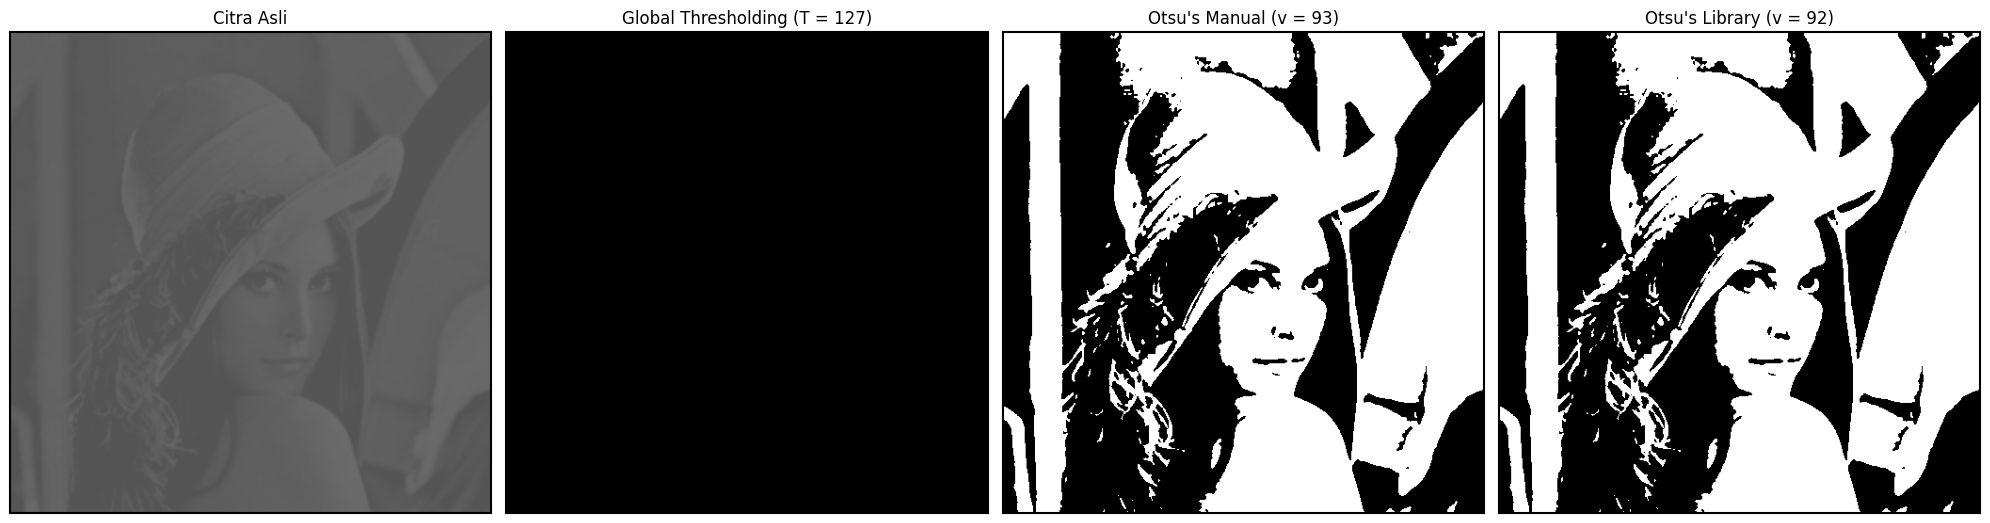

Manual vs library identik: True


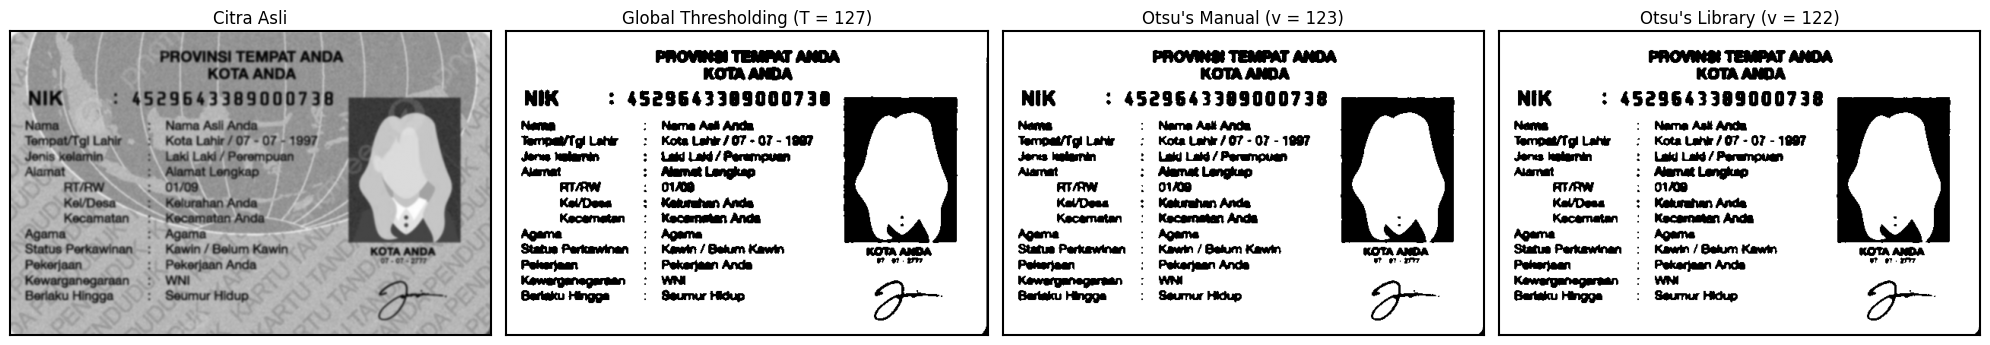

Manual vs library identik: True


In [ ]:
def otsu(gray):
    total = gray.size
    his, _ = np.histogram(gray, bins=np.arange(0, 257))
    intensity = np.arange(256)

    final_thresh, final_value = -1, -1
    for t in range(1, 256):
        pcb = his[:t].sum()
        pcf = his[t:].sum()
        if pcb == 0 or pcf == 0:
            continue

        Wb, Wf = pcb / total, pcf / total
        mub = (intensity[:t] * his[:t]).sum() / pcb
        muf = (intensity[t:] * his[t:]).sum() / pcf
        value = Wb * Wf * (mub - muf) ** 2

        if value > final_value:
            final_thresh, final_value = t, value

    final_img = np.where(gray >= final_thresh, 255, 0).astype(np.uint8)
    return final_img, final_thresh


def bandingkan(filename, thresh=127):
    img = cv.imread(filename, 0)
    blur = cv.GaussianBlur(img, (5, 5), 0)

    _, global_th = cv.threshold(blur, thresh, 255, cv.THRESH_BINARY)
    otsu_manual, t_manual = otsu(blur)
    t_lib, otsu_lib = cv.threshold(blur, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)

    titles = ['Citra Asli',
              f'Global Thresholding (T = {thresh})',
              f"Otsu's Manual (v = {t_manual})",
              f"Otsu's Library (v = {int(t_lib)})"]
    images = [blur, global_th, otsu_manual, otsu_lib]

    plt.figure(figsize=(20, 6))
    for i in range(4):
        ax = plt.subplot(1, 4, i + 1)
        ax.imshow(images[i], cmap='gray', vmin=0, vmax=255)
        ax.set_title(titles[i])
        ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values():
            s.set_linewidth(1.5)
    plt.tight_layout()
    plt.show()

    print("Manual vs library identik:", np.array_equal(otsu_manual, otsu_lib))


# A. Lena
bandingkan('/content/drive/MyDrive/pcvk_2026/Images/lena_gs_lc2.jpg')

# B. KTP sendiri
bandingkan('/content/drive/MyDrive/pcvk_2026/Images/ktp.jpg')

Seed dalam koin (36, 43) | intensitas: 159
   T=5: 21 piksel
   T=20: 919 piksel
   T=60: 15253 piksel
Seed latar (5, 200) | intensitas: 123
   T=5: 3052 piksel
   T=20: 9426 piksel
   T=60: 43330 piksel
Seed tepi koin (36, 22) | intensitas: 115
   T=5: 3295 piksel
   T=20: 12925 piksel
   T=60: 58669 piksel


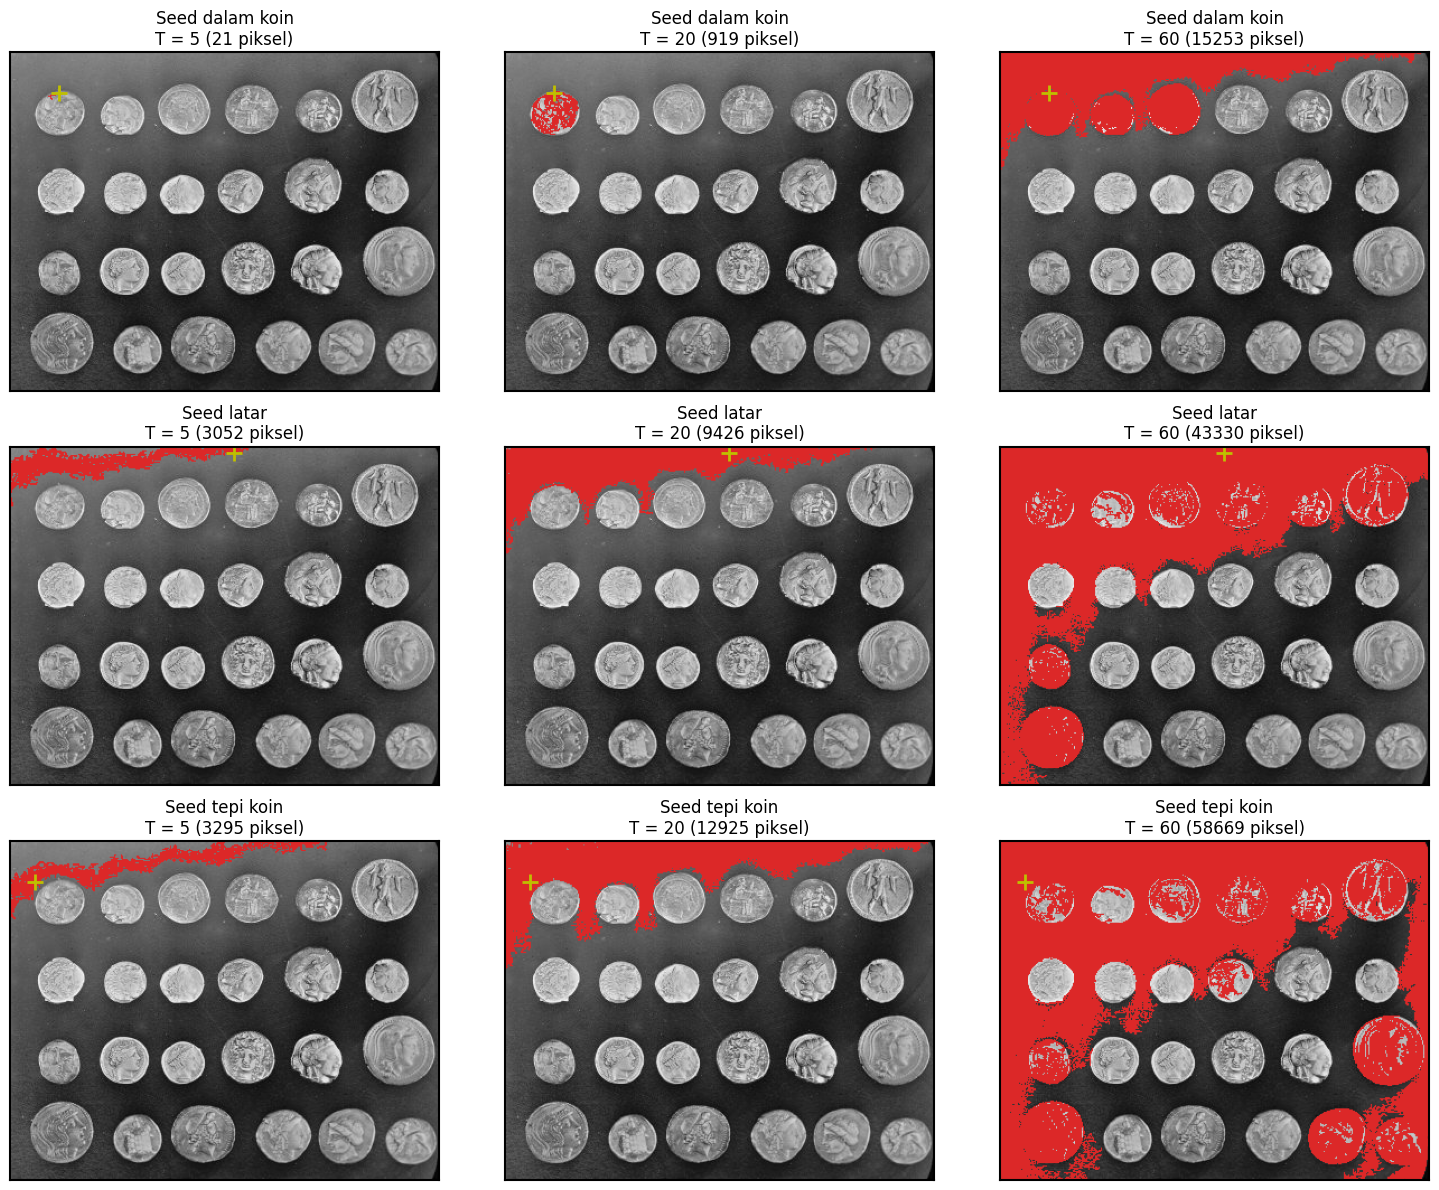

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.segmentation import flood

gray = data.coins()

seeds = {
    'Seed dalam koin': (36, 43),
    'Seed latar':      (5, 200),
    'Seed tepi koin':  (36, 22),
}
tolerances = [5, 20, 60]

fig, axes = plt.subplots(3, 3, figsize=(15, 12))

for r, (nama, seed) in enumerate(seeds.items()):
    print(f"{nama} {seed} | intensitas: {gray[seed]}")
    for c, T in enumerate(tolerances):
        region = flood(gray, seed_point=seed, tolerance=T, connectivity=1)

        overlay = np.dstack([gray, gray, gray]).astype(np.uint8)
        overlay[region] = [220, 40, 40]

        ax = axes[r, c]
        ax.imshow(overlay)
        ax.plot(seed[1], seed[0], 'y+', markersize=12, mew=2)
        ax.set_title(f"{nama}\nT = {T} ({region.sum()} piksel)")
        ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values():
            s.set_linewidth(1.5)
        print(f"   T={T}: {region.sum()} piksel")

plt.tight_layout()
plt.show()

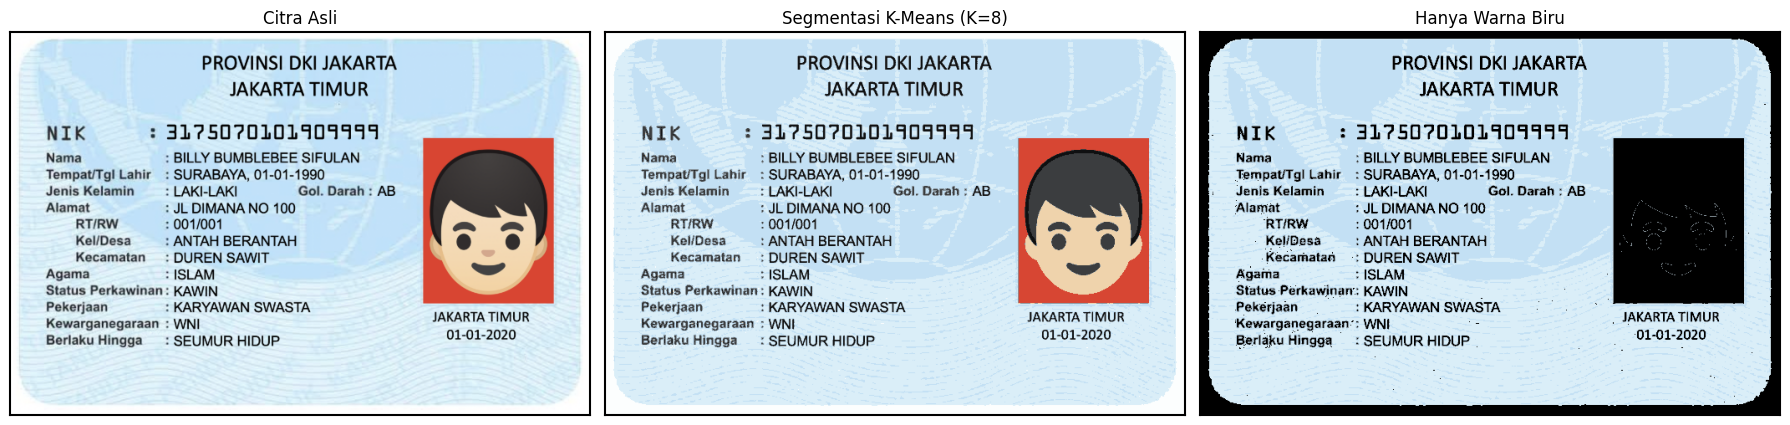

In [ ]:
img = cv.imread('/content/drive/MyDrive/pcvk_2026/Images/ktp_fulan.jpg')
img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)

K = 8
pixels = img_rgb.reshape(-1, 3).astype(np.float32)

kriteria = (cv.TERM_CRITERIA_EPS + cv.TERM_CRITERIA_MAX_ITER, 20, 1.0)
_, label, centers = cv.kmeans(pixels, K, None, kriteria, 5, cv.KMEANS_PP_CENTERS)

centers = centers.astype(np.uint8)
segmented = centers[label.flatten()].reshape(img_rgb.shape)

hsv = cv.cvtColor(segmented, cv.COLOR_RGB2HSV)
H, S, V = hsv[:, :, 0], hsv[:, :, 1], hsv[:, :, 2]

kelompok_biru = np.where((H >= 85) & (H <= 130) & (S >= 25) & (V >= 40), 1, 0)

hasil_biru = segmented.copy()
hasil_biru[kelompok_biru == 0] = 0

titles = ['Citra Asli', f'Segmentasi K-Means (K={K})', 'Hanya Warna Biru']
images = [img_rgb, segmented, hasil_biru]

plt.figure(figsize=(18, 5))
for i in range(3):
    ax = plt.subplot(1, 3, i + 1)
    ax.imshow(images[i])
    ax.set_title(titles[i])
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_linewidth(1.5)
plt.tight_layout()
plt.show()

In [ ]:
!apt-get -qq update
!apt-get -qq install tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...


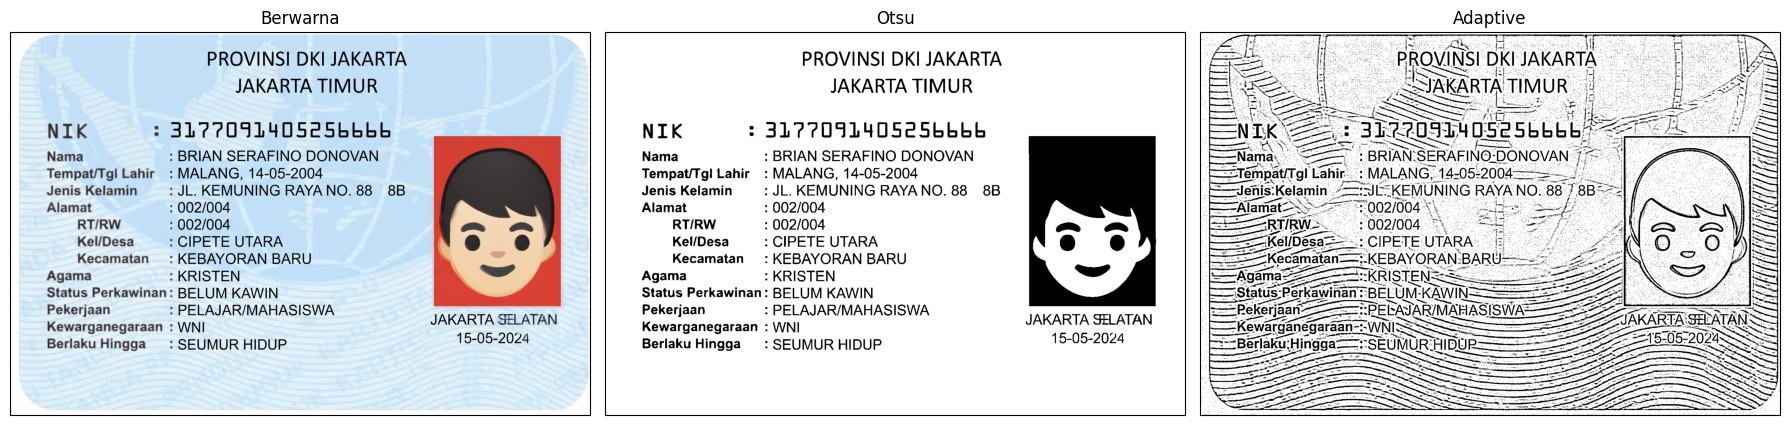

In [ ]:
import re
import cv2 as cv
import numpy as np
import pandas as pd
import pytesseract
import matplotlib.pyplot as plt
from pytesseract import Output

filename = '/content/drive/MyDrive/pcvk_2026/ktp_brian.jpg'
bgr = cv.imread(filename)
assert bgr is not None, "Gambar tidak terbaca: cek path / mount Drive"

skala = 1600 / bgr.shape[1]
bgr = cv.resize(bgr, None, fx=skala, fy=skala, interpolation=cv.INTER_CUBIC)

rgb = cv.cvtColor(bgr, cv.COLOR_BGR2RGB)
gray = cv.cvtColor(bgr, cv.COLOR_BGR2GRAY)

_, otsu = cv.threshold(gray, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
adaptive = cv.adaptiveThreshold(gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C,
                                cv.THRESH_BINARY, 11, 2)

citra = {'Berwarna': rgb, 'Otsu': otsu, 'Adaptive': adaptive}

plt.figure(figsize=(18, 5))
for i, (nama, im) in enumerate(citra.items()):
    ax = plt.subplot(1, 3, i + 1)
    ax.imshow(im, cmap=None if im.ndim == 3 else 'gray')
    ax.set_title(nama); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

In [ ]:
CONFIG = '--oem 3 --psm 6'
LANG = 'ind'

teks = {}
for nama, im in citra.items():
    teks[nama] = pytesseract.image_to_string(im, lang=LANG, config=CONFIG)
    print(f"========== {nama.upper()} ==========")
    print(teks[nama])

========== BERWARNA ==========
PROVINSI DKI JAKARTA
JAKARTA TIMUR
NIK : 3177091140505bbbb
Nama : BRIAN SERAFINO DONOVAN
Tempat/Tgl Lahir : MALANG, 14-05-2004
Jenis Kelamin : JL. KEMUNING RAYA NO. 88 8B
Alamat : 002/004
RT/RW : 002/004
KellDesa — : CIPETE UTARA ,
Kecamatan : KEBAYORAN BARU
Agama : KRISTEN
Status Perkawinan : BELUM KAWIN ssi
Pekerjaan : PELAJAR/MAHASISWA
Kewarganegaraan : WNI JAKARTA. aa
Berlaku Hingga — : SEUMUR HIDUP 15-05-2024

========== OTSU ==========
PROVINSI DKI JAKARTA
JAKARTA TIMUR
NIK : 317709110505bbbb
Nama : BRIAN SERAFINO DONOVAN
Tempat/Tgl Lahir : MALANG, 14-05-2004
Jenis Kelamin : JL. KEMUNING RAYA NO. 88 8B
Alamat : 002/004
RT/RW : 002/004
Kel/Desa : CIPETE UTARA
Kecamatan : KEBAYORAN BARU
Agama : KRISTEN
Status Perkawinan : BELUM KAWIN
Pekerjaan : PELAJAR/MAHASISWA
Kewarganegaraan : WNI JAKARTA SELATAN
Berlaku Hingga — : SEUMUR HIDUP 15-05-2024

========== ADAPTIVE ==========
—NIK An 31 R203IA OSg sbbb bee
— Nama AA : BRIANSERAFINO:DONOVAN 7“ 1. pre
“Te

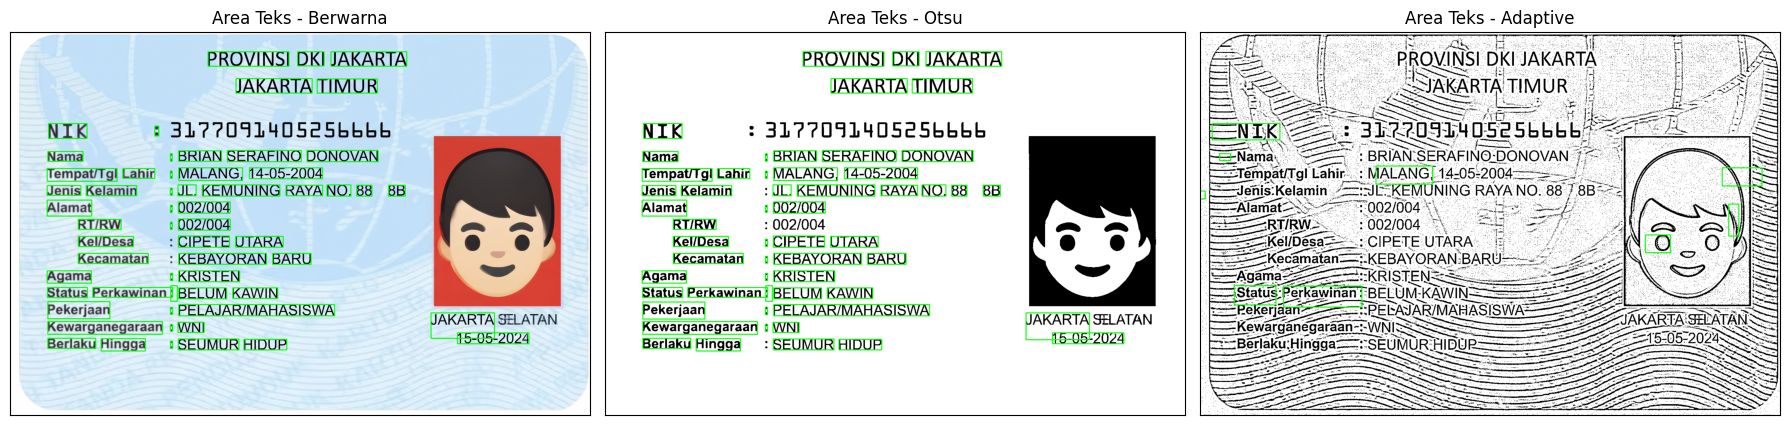

In [ ]:
BATAS_CONF = 60
data = {}
plt.figure(figsize=(18, 6))
for i, (nama, im) in enumerate(citra.items()):
    d = pytesseract.image_to_data(im, lang=LANG, config=CONFIG, output_type=Output.DICT)
    data[nama] = d
    kanvas = im.copy() if im.ndim == 3 else cv.cvtColor(im, cv.COLOR_GRAY2RGB)
    for j in range(len(d['text'])):
        kata, conf = d['text'][j].strip(), float(d['conf'][j])
        if kata and conf > BATAS_CONF:
            x, y, w, h = d['left'][j], d['top'][j], d['width'][j], d['height'][j]
            cv.rectangle(kanvas, (x, y), (x + w, y + h), (0, 255, 0), 2)
    ax = plt.subplot(1, 3, i + 1)
    ax.imshow(kanvas); ax.set_title(f'Area Teks - {nama}')
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

In [ ]:
acuan = ['PROVINSI', 'BRIAN', 'MALANG', '14-05-2004', 'KEMUNING',
         '002/004', 'CIPETE', 'KEBAYORAN', 'KRISTEN', 'PELAJAR/MAHASISWA']

def norm(s):
    return re.sub(r'\s+', ' ', s.strip().lower())

def ketemu(item, teks_ocr):
    pola = r'(?<!\w)' + re.escape(norm(item)) + r'(?!\w)'
    return re.search(pola, norm(teks_ocr)) is not None

def cari_terbaca(item, teks_ocr):
    """Tampilkan token OCR yang paling mirip untuk item yang gagal cocok."""
    token = re.findall(r'\S+', teks_ocr)
    from difflib import get_close_matches
    m = get_close_matches(item.lower(), [t.lower() for t in token], n=1, cutoff=0.4)
    return m[0] if m else '(tidak terbaca)'

baris = []
for no, item in enumerate(acuan, 1):
    row = {'No.': no, 'Teks sebenarnya': item}
    for nama in citra:
        row[f'OCR {nama}'] = item if ketemu(item, teks[nama]) else cari_terbaca(item, teks[nama])
    baris.append(row)

tabel = pd.DataFrame(baris)
display(tabel)

,No.,Teks sebenarnya,OCR Berwarna,OCR Otsu,OCR Adaptive
0,1,PROVINSI,PROVINSI,PROVINSI,perkawinan
1,2,BRIAN,BRIAN,BRIAN,ba
2,3,MALANG,MALANG,MALANG,MALANG
3,4,14-05-2004,14-05-2004,14-05-2004,14-05:2004-———....
4,5,KEMUNING,KEMUNING,KEMUNING,KEMUNING
5,6,002/004,002/004,002/004,f002/004
6,7,CIPETE,CIPETE,CIPETE,--:cipeteutara
7,8,KEBAYORAN,KEBAYORAN,KEBAYORAN,KEBAYORAN
8,9,KRISTEN,KRISTEN,KRISTEN,st
9,10,PELAJAR/MAHASISWA,PELAJAR/MAHASISWA,PELAJAR/MAHASISWA,perkawinan


In [ ]:
ringkasan = []
for nama in citra:
    tepat = sum(ketemu(it, teks[nama]) for it in acuan)
    conf_valid = [float(c) for c, t in zip(data[nama]['conf'], data[nama]['text'])
                  if t.strip() and float(c) >= 0]
    n_kotak = sum(c > BATAS_CONF for c in conf_valid)
    ringkasan.append({
        'Citra masukan OCR': nama,
        'Item terbaca tepat': f'{tepat}/{len(acuan)}',
        'Kecocokan (%)': tepat / len(acuan) * 100,
        'Rata-rata confidence': round(np.mean(conf_valid), 2) if conf_valid else 0,
        'Jumlah kata (conf>60)': n_kotak,
    })
display(pd.DataFrame(ringkasan))

,Citra masukan OCR,Item terbaca tepat,Kecocokan (%),Rata-rata confidence,Jumlah kata (conf>60)
0,Berwarna,10/10,100.0,84.39,59
1,Otsu,10/10,100.0,85.34,56
2,Adaptive,3/10,30.0,30.47,9


## Analisis Perbandingan OCR pada Citra Berwarna, Otsu, dan Adaptive

**Ringkasan hasil percobaan (10 item acuan, `--oem 3 --psm 6`, bahasa `ind`, batas confidence 60):**

| Citra masukan OCR | Item terbaca tepat | Kecocokan (%) | Rata-rata confidence | Jumlah kata (conf > 60) |
|---|---|---|---|---|
| Berwarna asli | 10/10 | 100.0 | 84.39 | 59 |
| Segmentasi Otsu | 10/10 | 100.0 | 85.34 | 56 |
| Segmentasi Adaptive | 3/10 | 30.0 | 30.47 | 9 |

### 1. Citra masukan mana yang menghasilkan pembacaan paling tepat?

Citra **berwarna asli** dan citra **hasil Otsu** sama-sama paling tepat, yaitu **10/10 item (100%)**. Citra hasil **Adaptive** jauh di bawahnya dengan hanya **3/10 item (30%)**, yaitu `MALANG`, `KEMUNING`, dan `KEBAYORAN`.

Antara Berwarna dan Otsu tidak ada pemenang tegas pada 10 item acuan. Perbedaannya terlihat pada hasil `image_to_string` secara keseluruhan: Otsu membaca baris `Kel/Desa : CIPETE UTARA` dan `Kewarganegaraan : WNI JAKARTA SELATAN` dengan bersih, sedangkan citra berwarna menghasilkan `KellDesa ... CIPETE UTARA ,` dan `WNI JAKARTA. aa`, serta sisa karakter `ssi` setelah `BELUM KAWIN`.

Catatan: kesepuluh item acuan tidak memuat NIK. Pada NIK, kedua metode sama-sama salah (lihat jawaban no. 2), sehingga kecocokan 100% tidak berarti seluruh teks pada KTP terbaca sempurna.

### 2. Kesalahan pembacaan

| No. | Citra | Teks sebenarnya | Hasil OCR | Jenis kesalahan |
|---|---|---|---|---|
| 1 | Berwarna | NIK `3177091405256666` | `3177091140505bbbb` | Angka salah dan urutan bergeser; angka 6 terbaca huruf `b` |
| 2 | Otsu | NIK `3177091405256666` | `317709110505bbbb` | Angka hilang dan salah; angka 6 terbaca huruf `b` |
| 3 | Berwarna | `Kel/Desa` | `KellDesa` | Huruf tertukar (`/` terbaca `l`) |
| 4 | Berwarna | `WNI` | `WNI JAKARTA. aa` | Karakter sisa (noise) ikut terbaca |
| 5 | Adaptive | `PROVINSI` | `perkawinan` | Teks salah baca total (item acuan tidak ditemukan) |
| 6 | Adaptive | `BRIAN SERAFINO DONOVAN` | `BRIANSERAFINO:DONOVAN` | Spasi hilang dan diganti tanda baca |
| 7 | Adaptive | `14-05-2004` | `14-05:2004-———....` | Tanda hubung terbaca titik dua dan ada karakter sisa |
| 8 | Adaptive | `KRISTEN` | `st` | Teks hampir tidak terbaca |

Kesalahan pada NIK terjadi di semua metode karena NIK memakai font khusus yang bentuk angkanya tidak umum (angka 6 mirip huruf `b`).

### 3. Apakah segmentasi selalu meningkatkan ketepatan OCR?

**Tidak.** Hasil percobaan menunjukkan dampak yang berbeda untuk tiap metode:

- **Otsu** menghasilkan kecocokan yang sama dengan citra berwarna (100% vs 100%), dengan rata-rata confidence sedikit lebih tinggi (85.34 vs 84.39). Otsu tidak menurunkan ketepatan, dan ia memberi hasil yang lebih rapi karena pola latar biru hilang. Namun ia belum memperbaiki kesalahan NIK.
- **Adaptive** justru **menurunkan kecocokan drastis** dari 100% menjadi 30%, dan rata-rata confidence turun dari 84.39 menjadi 30.47. Hanya 9 kata yang melewati batas confidence 60, dan beberapa kotak hijaunya jatuh pada wajah kartun, bukan pada teks.

Penyebabnya, Adaptive menghitung ambang dari jendela kecil 11×11 sehingga garis-garis halus pada latar KTP ikut dianggap sebagai objek dan menjadi garis hitam yang menimpa huruf. Jadi segmentasi hanya membantu bila metodenya cocok dengan karakter citra, dan salah memilih metode lebih merugikan daripada tidak melakukan segmentasi sama sekali.

### 4. Bagaimana warna atau pola latar belakang memengaruhi pembacaan teks?

- **Pola garis bergelombang dan gambar peta pada latar KTP** adalah faktor yang paling berpengaruh. Pada citra berwarna, pola ini berwarna biru muda yang kontrasnya rendah terhadap teks hitam, sehingga Tesseract hampir tidak terganggu (hanya muncul sisa karakter kecil seperti `ssi` dan `aa`).
- Setelah **Adaptive threshold**, pola yang sama berubah menjadi garis hitam pekat sehingga kontrasnya setara dengan huruf. Teks tertimpa garis, spasi antar kata hilang (`BRIANSERAFINO`, `CIPETEUTARA`), dan muncul karakter palsu.
- **Otsu** memakai satu ambang global. Karena latar biru muda jauh lebih terang daripada teks, seluruh latar menjadi putih bersih dan teks tetap hitam tegas. Pola latar yang tipis tidak lolos ambang sehingga hilang.
- **Foto wajah** berwarna merah dan hitam tidak memuat teks, tetapi pada Adaptive pola garis wajahnya sempat terdeteksi sebagai area teks.

Jadi warna latar yang terang dan merata lebih cocok ditangani threshold global (Otsu), sedangkan threshold lokal yang sensitif cenderung memunculkan pola latar sebagai noise.

### 5. Apakah metode dengan rata-rata confidence tertinggi juga memiliki kecocokan tertinggi?

Rata-rata confidence tertinggi dimiliki **Otsu (85.34)**, dan Otsu juga termasuk yang kecocokannya tertinggi (**100%**, seri dengan Berwarna). Pada percobaan ini arahnya searah: Adaptive memiliki confidence terendah (30.47) dan kecocokan terendah (30%).

Namun hubungan ini **tidak bisa dianggap pasti**:
- Selisih Otsu dan Berwarna hanya 0.95 poin, padahal kecocokan keduanya sama. Citra berwarna bahkan menghasilkan lebih banyak kata dengan confidence di atas 60 (59 vs 56).
- NIK terbaca salah pada Otsu dan Berwarna walaupun confidence rata-ratanya tinggi. Confidence adalah keyakinan Tesseract terhadap tebakannya sendiri, bukan jaminan bahwa tebakan itu benar.
- Rata-rata confidence hanya dihitung dari kata yang terdeteksi, sehingga tidak memperhitungkan teks yang tidak terdeteksi sama sekali.

Karena itu confidence sebaiknya dipakai bersama pengecekan terhadap teks acuan, bukan sebagai satu-satunya ukuran kualitas OCR.